<h1>Question 5</h1>

<>:80: SyntaxWarning: "\e" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\e"? A raw string is also an option.
<>:80: SyntaxWarning: "\e" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\e"? A raw string is also an option.
/var/folders/5_/2k_fvf4x0hgdk8mcpwllpt980000gn/T/ipykernel_4284/1362310808.py:80: SyntaxWarning: "\e" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\e"? A raw string is also an option.
  plt.plot(eps_regret, label='$\epsilon$-Greedy (0.1)')


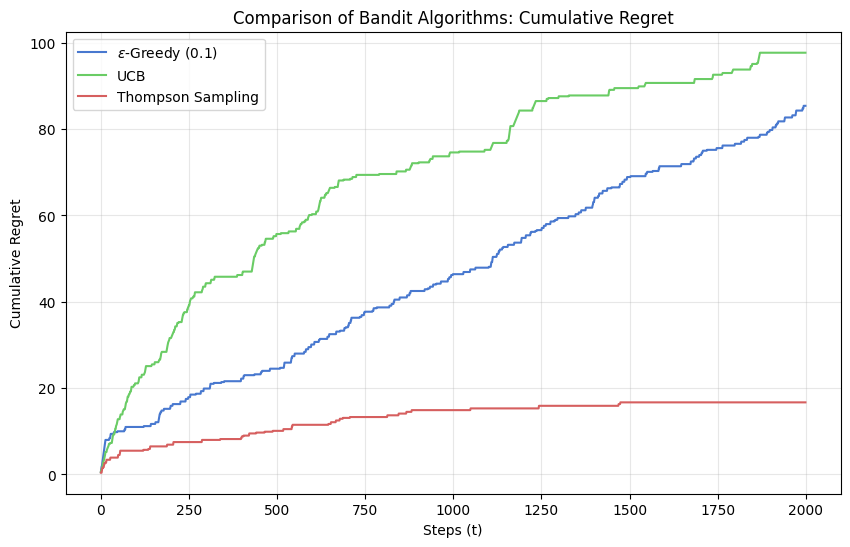

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# تنظیم دانه تصادفی برای تکرارپذیری (اجرای منصفانه)
np.random.seed(42)

class BernoulliBandit:
    def __init__(self, probabilities):
        self.probabilities = probabilities
        self.k = len(probabilities)
        self.optimal_prob = max(probabilities)

    def pull(self, arm_index):
        # تولید پاداش برنولی (0 یا 1)
        reward = 1 if np.random.random() < self.probabilities[arm_index] else 0
        regret = self.optimal_prob - self.probabilities[arm_index]
        return reward, regret

def simulate(bandit, T, algorithm, **kwargs):
    k = bandit.k
    counts = np.zeros(k) # تعداد دفعات انتخاب هر بازو
    values = np.zeros(k) # میانگین پاداش‌های هر بازو
    total_regret = 0
    regret_history = []
    
    # برای Thompson Sampling
    alphas = np.ones(k)
    betas = np.ones(k)

    for t in range(1, T + 1):
        if algorithm == 'epsilon_greedy':
            epsilon = kwargs.get('epsilon', 0.1)
            if np.random.random() < epsilon:
                arm = np.random.randint(k)
            else:
                arm = np.argmax(values)

        elif algorithm == 'ucb':
            # در ابتدا هر بازو باید حداقل یک بار انتخاب شود تا Ni > 0 باشد
            if t <= k:
                arm = t - 1
            else:
                uncertainty = np.sqrt((2 * np.log(t)) / counts)
                arm = np.argmax(values + uncertainty)

        elif algorithm == 'thompson':
            samples = np.random.beta(alphas, betas)
            arm = np.argmax(samples)

        # دریافت پاداش و محاسبه رگرت
        reward, regret = bandit.pull(arm)
        
        # بروزرسانی آمار برای Greedy و UCB
        counts[arm] += 1
        values[arm] += (reward - values[arm]) / counts[arm]
        
        # بروزرسانی آمار برای Thompson
        if reward == 1:
            alphas[arm] += 1
        else:
            betas[arm] += 1

        total_regret += regret
        regret_history.append(total_regret)

    return regret_history

# تنظیمات شبیه‌سازی
T = 2000
true_probs = [0.1, 0.3, 0.7, 0.2, 0.5] # بازوی سوم با 0.7 بهترین است
bandit = BernoulliBandit(true_probs)

# اجرای الگوریتم‌ها
eps_regret = simulate(bandit, T, 'epsilon_greedy', epsilon=0.1)
ucb_regret = simulate(bandit, T, 'ucb')
ts_regret = simulate(bandit, T, 'thompson')

# رسم نمودار
plt.figure(figsize=(10, 6))
plt.plot(eps_regret, label=r'$\epsilon$-Greedy (0.1)')
plt.plot(ucb_regret, label='UCB')
plt.plot(ts_regret, label='Thompson Sampling')
plt.xlabel('Steps (t)')
plt.ylabel('Cumulative Regret')
plt.title('Comparison of Bandit Algorithms: Cumulative Regret')
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('Q5-bandit_algorithms_comparison.png', dpi=300)
plt.show()

<h1>Question 6</h1>

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# تنظیم دانه تصادفی برای تکرارپذیری
np.random.seed(42)

def estimate_optimal_probabilities(alphas, betas, num_samples=10000):
    """
    تخمین احتمال بهینه بودن هر بازو با استفاده از شبیه‌سازی مونت‌کارلو
    """
    k = len(alphas)
    # نمونه‌برداری از توزیع بتای هر بازو به تعداد num_samples بار
    samples = np.random.beta(alphas, betas, size=(num_samples, k))
    
    # پیدا کردن اندیس بازوی برنده در هر تکرار
    winners = np.argmax(samples, axis=1)
    
    # محاسبه فراوانی برنده شدن هر بازو
    probs = np.zeros(k)
    for i in range(k):
        probs[i] = np.mean(winners == i)
    return probs

def run_ts_and_compare(true_probs, T_list):
    k = len(true_probs)
    
    for T in T_list:
        alphas = np.ones(k)
        betas = np.ones(k)
        arm_counts = np.zeros(k)
        
        # اجرای Thompson Sampling
        for t in range(T):
            theta = np.random.beta(alphas, betas)
            arm = np.argmax(theta)
            
            # شبیه‌سازی پاداش
            reward = 1 if np.random.random() < true_probs[arm] else 0
            
            # بروزرسانی
            alphas[arm] += reward
            betas[arm] += (1 - reward)
            arm_counts[arm] += 1
            
        # ۱. تخمین احتمال بهینه بودن با مونت کارلو (بر اساس پسین نهایی)
        estimated_probs = estimate_optimal_probabilities(alphas, betas)
        
        # ۲. محاسبه فراوانی تجربی انتخاب بازوها توسط TS
        empirical_frequencies = arm_counts / T
        
        # ۳. محاسبه همبستگی (Correlation)
        correlation = np.corrcoef(estimated_probs, empirical_frequencies)[0, 1]
        
        print(f"Results for T = {T}:")
        print(f"  True Probs: {true_probs}")
        print(f"  Estimated Optimal Probs (MC): {np.round(estimated_probs, 3)}")
        print(f"  Empirical Frequencies (TS): {np.round(empirical_frequencies, 3)}")
        print(f"  Correlation: {correlation:.4f}")
        print("-" * 30)

# تنظیمات محیط
true_probabilities = [0.2, 0.5, 0.75, 0.4] # بازوی سوم (اندیس 2) بهترین است
T_values = [500, 1000, 5000]

run_ts_and_compare(true_probabilities, T_values)

Results for T = 500:
  True Probs: [0.2, 0.5, 0.75, 0.4]
  Estimated Optimal Probs (MC): [0.001 0.016 0.981 0.002]
  Empirical Frequencies (TS): [0.024 0.058 0.898 0.02 ]
  Correlation: 0.9997
------------------------------
Results for T = 1000:
  True Probs: [0.2, 0.5, 0.75, 0.4]
  Estimated Optimal Probs (MC): [0.    0.    0.998 0.002]
  Empirical Frequencies (TS): [0.005 0.051 0.936 0.008]
  Correlation: 0.9989
------------------------------
Results for T = 5000:
  True Probs: [0.2, 0.5, 0.75, 0.4]
  Estimated Optimal Probs (MC): [0.    0.002 0.998 0.001]
  Empirical Frequencies (TS): [0.002 0.015 0.978 0.006]
  Correlation: 1.0000
------------------------------


<h1>Question 7</h1>

<>:105: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:105: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
/var/folders/5_/2k_fvf4x0hgdk8mcpwllpt980000gn/T/ipykernel_4284/2720940480.py:105: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
  axes[1].set_xticklabels([f'Arm {i+1}\n($\mu$={TRUE_MEANS[i]})' for i in range(K)])


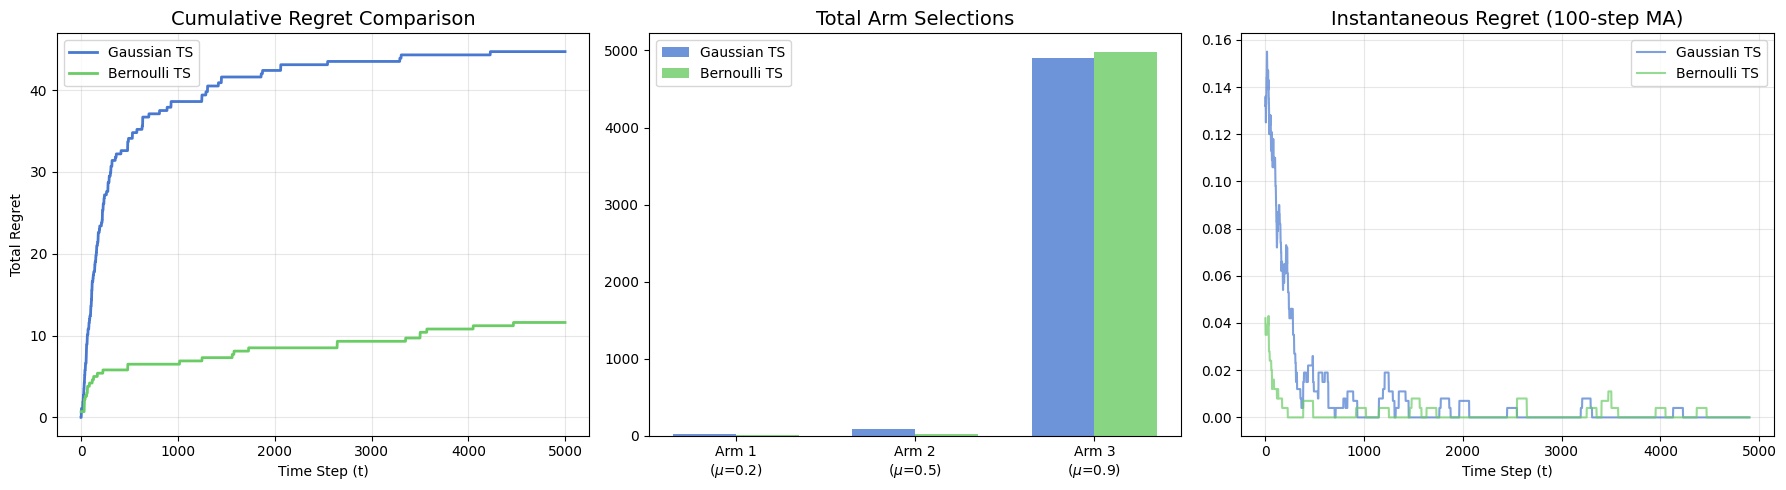

Algorithm       | Total Regret    | Best Arm Selections 
-------------------------------------------------------
Gaussian TS     | 44.70           | 4901.0 (98.0%)
Bernoulli TS    | 11.60           | 4974.0 (99.5%)


In [10]:
import numpy as np
import matplotlib.pyplot as plt

# Set seed for reproducibility and fair comparison
np.random.seed(42)

# Simulation Parameters
K = 3  # Number of arms
TRUE_MEANS = np.array([0.2, 0.5, 0.9])
SIGMA_REWARD = 1.0  # Known noise standard deviation (sigma^2 = 1.0)
T = 5000  # Total time steps

def gaussian_thompson_sampling():
    """Implementation of Thompson Sampling with Gaussian rewards and priors."""
    # Prior initialization: mu ~ N(0, 10)
    mu_priors = np.zeros(K)
    sigma2_priors = np.ones(K) * 10.0
    
    cumulative_regret = np.zeros(T)
    arm_counts = np.zeros(K)
    optimal_mean = np.max(TRUE_MEANS)
    total_regret = 0
    
    for t in range(T):
        # 1. Sampling from posterior distributions
        samples = np.random.normal(mu_priors, np.sqrt(sigma2_priors))
        arm = np.argmax(samples)
        arm_counts[arm] += 1
        
        # 2. Observe Reward (Gaussian)
        reward = np.random.normal(TRUE_MEANS[arm], SIGMA_REWARD)
        
        # 3. Regret Calculation
        total_regret += (optimal_mean - TRUE_MEANS[arm])
        cumulative_regret[t] = total_regret
        
        # 4. Bayesian Update (Normal-Normal Conjugate)
        # Standard formulas for posterior variance and mean
        precision_prior = 1.0 / sigma2_priors[arm]
        precision_reward = 1.0 / (SIGMA_REWARD**2)
        
        post_variance = 1.0 / (precision_prior + precision_reward)
        post_mean = post_variance * (mu_priors[arm] * precision_prior + reward * precision_reward)
        
        mu_priors[arm] = post_mean
        sigma2_priors[arm] = post_variance
        
    return cumulative_regret, arm_counts

def bernoulli_thompson_sampling():
    """Implementation of Thompson Sampling with Beta-Bernoulli model."""
    alphas = np.ones(K)
    betas = np.ones(K)
    
    cumulative_regret = np.zeros(T)
    arm_counts = np.zeros(K)
    optimal_mean = np.max(TRUE_MEANS)
    total_regret = 0
    
    for t in range(T):
        # 1. Sampling from Beta posteriors
        samples = np.random.beta(alphas, betas)
        arm = np.argmax(samples)
        arm_counts[arm] += 1
        
        # 2. Observe Reward (Bernoulli)
        reward = 1 if np.random.random() < TRUE_MEANS[arm] else 0
        
        # 3. Regret Calculation
        total_regret += (optimal_mean - TRUE_MEANS[arm])
        cumulative_regret[t] = total_regret
        
        # 4. Bayesian Update
        if reward == 1:
            alphas[arm] += 1
        else:
            betas[arm] += 1
            
    return cumulative_regret, arm_counts

# Run Simulations
regret_g, counts_g = gaussian_thompson_sampling()
regret_b, counts_b = bernoulli_thompson_sampling()

# Visualization
plt.style.use('seaborn-v0_8-muted') # Stylish plotting style
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Cumulative Regret
axes[0].plot(regret_g, label='Gaussian TS', linewidth=2)
axes[0].plot(regret_b, label='Bernoulli TS', linewidth=2)
axes[0].set_title('Cumulative Regret Comparison', fontsize=14)
axes[0].set_xlabel('Time Step (t)')
axes[0].set_ylabel('Total Regret')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot 2: Arm Selection Frequency
x = np.arange(K)
width = 0.35
axes[1].bar(x - width/2, counts_g, width, label='Gaussian TS', alpha=0.8)
axes[1].bar(x + width/2, counts_b, width, label='Bernoulli TS', alpha=0.8)
axes[1].set_title('Total Arm Selections', fontsize=14)
axes[1].set_xticks(x)
axes[1].set_xticklabels([f'Arm {i+1}\n($\\mu$={TRUE_MEANS[i]})' for i in range(K)])
axes[1].legend()

# Plot 3: Instantaneous Regret (Moving Average)
window = 100
def moving_average(data):
    instant_regret = np.diff(np.insert(data, 0, 0))
    return np.convolve(instant_regret, np.ones(window)/window, mode='valid')

axes[2].plot(moving_average(regret_g), label='Gaussian TS', alpha=0.7)
axes[2].plot(moving_average(regret_b), label='Bernoulli TS', alpha=0.7)
axes[2].set_title(f'Instantaneous Regret ({window}-step MA)', fontsize=14)
axes[2].set_xlabel('Time Step (t)')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('Q7-gaussian_vs_bernoulli.png', dpi=200, bbox_inches='tight')
plt.show()

# Print Final Summary
print(f"{'Algorithm':<15} | {'Total Regret':<15} | {'Best Arm Selections':<20}")
print("-" * 55)
print(f"{'Gaussian TS':<15} | {regret_g[-1]:<15.2f} | {counts_g[2]} ({counts_g[2]/T*100:.1f}%)")
print(f"{'Bernoulli TS':<15} | {regret_b[-1]:<15.2f} | {counts_b[2]} ({counts_b[2]/T*100:.1f}%)")